<a href="https://colab.research.google.com/github/vigneshkv200/HR_RAG/blob/main/RAG_proj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IIA HR Policy Assistant — RAG Chatbot
**LangChain · Sentence-Transformers · FAISS · Google Gemini · RAGAS**
DataMites AI Engineering Track — AI Client Project 5 (Intelligent RAG-Based Chatbot)

---

## 1. Problem Domain Description

**Use case.** Employees and HR staff of the Indian Industries Association (IIA) regularly need exact answers from the HR policy: how many casual leaves they get, how Earned Leave is credited, what the notice period is, who can take an interest-free loan, and so on. Searching a 47-page PDF by hand is slow, and a general-purpose LLM cannot be trusted here because it has never seen IIA's policy and will confidently invent numbers. This project builds a **Retrieval-Augmented Generation (RAG) chatbot** that answers HR-policy questions *only* from the official document and tells the user which page the answer came from.

**Knowledge base (Option D — custom domain).** *IIA HR Policy, Revision 1.1* (PDF, 47 pages). It covers 18 policy sections — recruitment and selection, training, dress code, performance appraisal, pay and benefits, interest-free loans, TA/DA, promotions, grievance redressal, cessation of employment, transfers, leave, discipline and culture, gender policy, safety, and the power to amend the policy — plus 9 annexures (cadre structure, forms, and the DAFP / WAFP / MPA performance formats).

**Why RAG and not just an LLM.** The answers are specific facts (10 casual leaves, 60 days Earned Leave cap, 7 days of unauthorised absence, ...) that change when the policy is revised. RAG keeps the facts in the document, retrieves the relevant passages at question time, and forces the model to answer from them. This reduces hallucination and makes every answer checkable against a page number.

**Behaviour for out-of-scope questions.** If the retrieved passages do not contain the answer, the bot must say *"I cannot find this in the IIA HR Policy document."* instead of guessing. This is tested explicitly with out-of-domain questions.

**Success criteria.**
1. Retrieval: the correct policy page is among the top-k retrieved chunks (hit-rate and MRR).
2. Answer quality: RAGAS **faithfulness**, **answer relevancy**, **context precision** and **context recall**.
3. Safety: out-of-domain questions are refused, in-domain questions are not wrongly refused.

## 2. Pipeline overview (maps to the project brief)

| Brief step | What this notebook does |
|---|---|
| 1. Document ingestion | `PyPDFLoader` loads the policy PDF page by page |
| 2. Chunking | `RecursiveCharacterTextSplitter` (800 chars, 150 overlap) |
| 3. Embedding | `all-MiniLM-L6-v2` (sentence-transformers, free, local) |
| 4. Vector store | FAISS index, saved to disk and reloaded to prove reproducibility |
| 5. Query processing | Query embedded, top-k chunks retrieved |
| 6. Augmented prompt | Retrieved chunks + page numbers injected into a strict prompt |
| 7. Generation | Gemini via `langchain-google-genai` |
| 8. Interface | CLI chat function |
| Evaluation | 17 questions, RAGAS metrics, retrieval metrics, chunk-size comparison |
| Documentation | `README.md`, architecture diagram, `requirements.txt` generated at the end |

## 3. How to run
1. Run the cells **top to bottom**.
2. After the install cell, if Colab asks you to **restart the runtime**, restart it and continue from the next cell.
3. You will be asked to paste your **Gemini API key** (hidden input) and to **upload the IIA HR Policy PDF**.
4. If the free tier hits a rate limit (429), the notebook waits and retries. If your daily quota is exhausted, re-run the API-key cell with another key and re-run the same cell that stopped — finished questions are remembered and are not repeated.

In [ ]:
# Step 0 — Install dependencies (about 1-2 minutes). Restart the runtime if Colab asks.
!pip install -q "langchain>=0.3,<0.4" "langchain-core>=0.3,<0.4" "langchain-community>=0.3,<0.4" "langchain-text-splitters>=0.3,<0.4" "langchain-huggingface>=0.3,<0.4" "langchain-google-genai>=2.1,<3" faiss-cpu pypdf sentence-transformers "ragas==0.2.15" datasets matplotlib pandas

In [ ]:
# Imports and configuration (edit the values in the CONFIG block if you want)
import os, re, time, json, zipfile, getpass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_google_genai import ChatGoogleGenerativeAI

# ------------------------------ CONFIG ------------------------------
MODEL_NAME = "gemini-3.5-flash-lite"   # change if your model list shows a better/available one
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
CHUNK_SIZE = 800          # characters
CHUNK_OVERLAP = 150
TOP_K = 4                 # chunks retrieved per question
INDEX_DIR = "faiss_index_iia"
SLEEP_BETWEEN_CALLS = 4   # seconds, keeps the free tier under the per-minute limit

RUN_RAGAS = True          # RAGAS needs many Gemini calls (about 10-20 minutes on the free tier)
RAGAS_LIMIT = None        # e.g. 5 to test RAGAS on only the first 5 in-domain questions
RUN_LLM_JUDGE = True      # second opinion: custom LLM-as-judge (15 extra calls)
# --------------------------------------------------------------------

NOT_FOUND = "I cannot find this in the IIA HR Policy document."
print("Imports OK")

Imports OK


In [ ]:
# Gemini API key — you will be asked to paste it (input is hidden)
API_KEY = getpass.getpass("Enter your Gemini API key: ").strip()
os.environ["GOOGLE_API_KEY"] = API_KEY

llm = ChatGoogleGenerativeAI(
    model=MODEL_NAME,
    google_api_key=API_KEY,
    temperature=0,
    max_retries=2,
)

def _to_text(content):
    """Gemini can return a string or a list of parts; always give back plain text."""
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        parts = []
        for p in content:
            if isinstance(p, str):
                parts.append(p)
            elif isinstance(p, dict) and p.get("text"):
                parts.append(p["text"])
        return "".join(parts)
    return str(content)

def call_llm(prompt, max_attempts=6):
    """Call Gemini and wait/retry when the free tier returns a 429 rate-limit error."""
    wait = 20
    for attempt in range(1, max_attempts + 1):
        try:
            return _to_text(llm.invoke(prompt).content).strip()
        except Exception as e:
            msg = str(e)
            rate_limited = any(s in msg for s in ("429", "RESOURCE_EXHAUSTED", "quota"))
            if rate_limited and attempt < max_attempts:
                print(f"  rate limit hit - waiting {wait}s (attempt {attempt}/{max_attempts})")
                time.sleep(wait)
                wait = min(wait * 2, 120)
            else:
                if rate_limited:
                    print("  Quota looks exhausted. Re-run this key cell with another API key, then re-run the cell that stopped.")
                raise

print(call_llm("Reply with exactly one word: ready"))

Enter your Gemini API key: ··········
Ready


## Step 1 — Document ingestion
Upload the IIA HR Policy PDF (the cell asks for it only if no PDF is already in the Colab folder).

In [ ]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

pdf_candidates = sorted(Path(".").glob("*.pdf"))
if not pdf_candidates and IN_COLAB:
    files.upload()
    pdf_candidates = sorted(Path(".").glob("*.pdf"))
if not pdf_candidates:
    raise FileNotFoundError("No PDF found. Upload the IIA HR Policy PDF into the working folder.")

PDF_PATH = str(pdf_candidates[0])
print("Using PDF:", PDF_PATH, "| all PDFs found:", [str(p) for p in pdf_candidates])

pages = PyPDFLoader(PDF_PATH).load()

HEADER_RE = re.compile(r"IIA\s*HR\s*POLICY\s*REVISION\s*1\.1\s*\d*", re.IGNORECASE)
for p in pages:
    text = HEADER_RE.sub(" ", p.page_content)      # remove the repeated page header
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text).strip()
    p.page_content = text
    p.metadata["page"] = int(p.metadata.get("page", 0)) + 1   # 1-based page numbers
    p.metadata["source"] = Path(PDF_PATH).name

print("Pages loaded:", len(pages))
nearly_empty = [p.metadata["page"] for p in pages if len(p.page_content) < 50]
if nearly_empty:
    print("Pages with almost no text (could be images/scans):", nearly_empty)

Using PDF: IIA HR Policy.pdf | all PDFs found: ['IIA HR Policy.pdf']
Pages loaded: 47
Pages with almost no text (could be images/scans): [43, 47]


In [ ]:
# Quick look at a few pages to confirm the text was extracted properly
for p in pages[18:20]:
    print("PAGE", p.metadata["page"], "|", len(p.page_content), "characters")
    print(p.page_content[:600])
    print("-" * 70)

PAGE 19 | 2145 characters
14. Leave Policy 
✓ Casual Leaves: The maximum period of Casual Leave which a staff is allowed to avail is 
10 days in calendar year. Sundays and Holidays falling during a period of Casual Leave 
will not be treated as a part of casual leave. Casual leaves not availed during the year will 
not be carried forward to next calendar year. 
✓ Earned Leave: After completion of 1 year in IIA employee will be given 15 earned leave. 
Earned leaves will be credited in January each year for the previous year proportionate to 
regular attendance in the Office excluding un-authorised absence / leave withou
----------------------------------------------------------------------
PAGE 20 | 1876 characters
In case of emergency, the superior must be informed over phone or by other means to be 
followed up later with a written request in the prescribed application form. 
Encashment of Earned Leave: The earn leave at maximum of 60 days can be encashed. The 
earn leave can be accum

## Step 2 — Chunking
Pages are split into overlapping chunks. The splitter prefers paragraph and sentence boundaries, so a rule is less likely to be cut in half.

In [ ]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " ", ""],
)
chunks = splitter.split_documents(pages)
for i, c in enumerate(chunks):
    c.metadata["chunk_id"] = i

lengths = [len(c.page_content) for c in chunks]
print(f"Chunks: {len(chunks)} | avg length: {np.mean(lengths):.0f} chars | min: {min(lengths)} | max: {max(lengths)}")
print("\nSample chunk (page", chunks[30].metadata["page"], "):\n", chunks[30].page_content)

Chunks: 125 | avg length: 628 chars | min: 11 | max: 799

Sample chunk (page 11 ):
 Executive staff. 
● The Executive Head or any other functionary who has to attend some meeting, gathering 
on professional or social course, may wear dress in accordance with demand of the place, 
occasion and gathering. 
● In normal set of conditions: Shirt Trouser with other accessories of prescribed color and 
design 
● For female employees where serious health issues crop up, they may be allowed to wear 
Saree and Blouse or Salwar Kurta for convenience of prescribed color and design. 
ΙΙΑ will provide dress to all its employees as under:- 
● 2 Sets of Trouser +Shirt once a year. 
● Formal Shoes once a year 
● One Blazer once in two years for Executives and One Jacket for Non -Executives. 
● Management has the right to discontinue / hold the uniform policy only if a


## Steps 3 & 4 — Embeddings and vector store (FAISS)
Embeddings are normalised, so similarity search behaves like cosine similarity. The index is saved to disk and loaded back to prove the vector store is reproducible.

In [ ]:
embeddings = HuggingFaceEmbeddings(
    model_name=EMBED_MODEL,
    encode_kwargs={"normalize_embeddings": True},
)

vectorstore = FAISS.from_documents(chunks, embeddings)
vectorstore.save_local(INDEX_DIR)
print("Index saved to:", INDEX_DIR, "->", os.listdir(INDEX_DIR))

# Reload from disk and use the reloaded copy from here on
vectorstore = FAISS.load_local(INDEX_DIR, embeddings, allow_dangerous_deserialization=True)
print("Vectors in reloaded index:", vectorstore.index.ntotal, "| chunks:", len(chunks),
      "| match:", vectorstore.index.ntotal == len(chunks))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Index saved to: faiss_index_iia -> ['index.faiss', 'index.pkl']
Vectors in reloaded index: 125 | chunks: 125 | match: True


## Steps 5, 6 & 7 — Query processing, augmented prompt and generation
The prompt forces the model to use only the retrieved context, cite pages, and refuse when the answer is not there.

In [ ]:
def format_context(docs):
    return "\n\n".join(f"[Page {d.metadata['page']}]\n{d.page_content}" for d in docs)

def build_prompt(question, docs):
    return f"""You are the IIA HR Policy Assistant for the Indian Industries Association.
Answer the question using ONLY the context below, which comes from the IIA HR Policy document.
Rules:
- Do not use outside knowledge and do not guess.
- If the context does not contain the answer, reply exactly: {NOT_FOUND}
- Be concise and precise; keep numbers, limits and conditions exactly as written.
- Mention the page number(s) you used, like (p. 19).

CONTEXT:
{format_context(docs)}

QUESTION: {question}

ANSWER:"""

def rag_answer(question, store=None, k=TOP_K):
    """Full RAG pipeline for one question. Returns the answer plus the evidence used."""
    store = store or vectorstore
    docs = store.similarity_search(question, k=k)            # Step 5: retrieve
    prompt = build_prompt(question, docs)                    # Step 6: augment
    answer = call_llm(prompt)                                # Step 7: generate
    return {
        "question": question,
        "answer": answer,
        "docs": docs,
        "contexts": [d.page_content for d in docs],
        "pages": [d.metadata["page"] for d in docs],
    }

demo_questions = [
    "How many casual leaves can an employee take in a year?",
    "What is the notice period if an employee resigns?",
    "What is the capital of France?",
]
for q in demo_questions:
    r = rag_answer(q)
    print("Q:", q)
    print("A:", r["answer"])
    print("Pages retrieved:", r["pages"])
    print("-" * 70)
    time.sleep(SLEEP_BETWEEN_CALLS)

Q: How many casual leaves can an employee take in a year?
A: The maximum period of Casual Leave which a staff is allowed to avail is 10 days in calendar year (p. 19).
Pages retrieved: [19, 19, 20, 17]
----------------------------------------------------------------------
Q: What is the notice period if an employee resigns?
A: If an employee wants to resign from the job, it is necessary to give 1 month clear notice for the same or deposit one month salary if desires to leave immediately (p. 22).
Pages retrieved: [17, 18, 22, 17]
----------------------------------------------------------------------
Q: What is the capital of France?
A: I cannot find this in the IIA HR Policy document.
Pages retrieved: [47, 32, 32, 32]
----------------------------------------------------------------------


## Evaluation set (17 questions)
* **Q1-Q12** — single-topic questions on leave, discipline, transfers, pay, probation and loans.
* **Q13** — a multi-part question (office timings and late-arrival deductions).
* **Q14** — a list-type question (documents needed before an appointment letter)
* **Q15-Q17** — *out-of-domain* questions. The correct behaviour is to refuse.

The ground-truth answers were written from the IIA HR Policy PDF, and every fact was checked against the page it comes from. `target_pages` is the exact PDF page where each answer is written; page numbers match the printed page numbers.

The ground-truth answers below were supplied from the IIA HR Policy text and written in your own words. **Check each one against your PDF before submitting** and edit any that differ. `target_pages` is the page range where the answer should be found, taken from the policy's table of contents; adjust it if your PDF's page numbers differ.

In [ ]:
R = lambda a, b: set(range(a, b + 1))
NOT_IN_DOC = "NOT_IN_DOCUMENT"

EVAL_SET = [
    dict(id=1, category="in-domain",
         question="How many casual leaves can an employee get in a calendar year?",
         ground_truth="A staff member can avail a maximum of 10 days of Casual Leave in a calendar year. Sundays and holidays falling during a period of casual leave are not treated as part of the casual leave.",
         target_pages={19}),
    dict(id=2, category="in-domain",
         question="Can casual leaves be carried forward to the next year?",
         ground_truth="No. Casual leaves not availed during the year are not carried forward to the next calendar year.",
         target_pages={19}),
    dict(id=3, category="in-domain",
         question="What is the policy on discipline, moral, and employee conduct?",
         ground_truth="IIA expects its employees to maintain a high standard of moral and professional conduct and efficient work performance. Misconduct includes insubordination, disobedience, refusal of duties, sexual harassment of a colleague, and absence without leave or overstaying leave. Carelessness in duty means inaction, non-performance or delayed performance. Disciplinary actions are reprimand (verbal or written, without formal inquiry), censure (for habitual misconduct, on a supervisor's written report) and removal from post (without notice for temporary employees, after formal inquiry for permanent employees).",
         target_pages={20, 21}),
    dict(id=4, category="in-domain",
         question="What is the maximum limit for encashment of Earned Leave?",
         ground_truth="A maximum of 60 days of earned leave can be encashed.",
         target_pages={20}),
    dict(id=5, category="in-domain",
         question="What happens if an employee is absent without leave?",
         ground_truth="Unauthorised absence from duty for a continuous period of 7 days makes the person lose the job as a matter of indiscipline. An employee absent for 15 consecutive working days without notice is deemed to have quit, which counts as a resignation. Absence without leave is also listed as misconduct.",
         target_pages={17, 18, 20, 21}),
    dict(id=6, category="in-domain",
         question="Who decides the public holidays for the head office and chapter offices?",
         ground_truth="The 10 public/national holidays in a year are decided by PSGT (President, Senior Vice President, General Secretary and Treasurer) for the Head Office and all Chapter Offices.",
         target_pages={19}),
    dict(id=7, category="in-domain",
         question="What is the maximum period of leave without pay allowed?",
         ground_truth="A maximum of 30 days in a calendar year, with prior permission and justification from the Appointing Authority.",
         target_pages={19}),
    dict(id=8, category="in-domain",
         question="What is the policy on transfers within the organization?",
         ground_truth="IIA reserves the right to transfer any employee to any of its offices in the interest of the organization, after taking the employee into confidence. The employee is entitled to one-time transportation and travelling expenses for self and family. Choice of work place is never the employee's right. An employee transferred to another district or state gets one week (7 days) of joining time; a transfer within the same city or district carries no transfer grant or joining time.",
         target_pages={18}),
    dict(id=9, category="in-domain",
         question="How is Earned Leave credited to an employee each year?",
         ground_truth="After completing 1 year in IIA an employee is given 15 earned leaves. They are credited in January each year for the previous year, proportionate to regular attendance and excluding unauthorised absence and leave without pay. Fractions are rounded off to 1 if 0.5 or more and to 0 if below 0.5.",
         target_pages={19}),
    dict(id=10, category="in-domain",
         question="On which date of the month are employees paid their salary?",
         ground_truth="The pay-day for Executive and Non-executive staff is the 7th day of each month.",
         target_pages={12}),
    dict(id=11, category="in-domain",
         question="What is the probation period for newly appointed employees, and can it be extended?",
         ground_truth="All newly appointed regular employees are on probation for six months, followed by confirmation subject to satisfactory performance. If performance is not satisfactory, the competent authority may extend the probation by a maximum of six months or terminate the services of the probationer without assigning any reason.",
         target_pages={9, 17}),
    dict(id=12, category="in-domain",
         question="Who is eligible for an interest-free loan, and what are the conditions?",
         ground_truth="Permanent employees who have completed 3 years of service are eligible for an interest-free loan or advance for specific purposes or emergencies. The maximum is two months of consolidated salary, recovered in 12 monthly instalments or fewer, starting from the month after payment. The President IIA is the sanctioning authority. Higher amounts or longer repayment are considered only in exceptional circumstances. It is subject to availability of funds and assessment of need and cannot be claimed as a right. Grounds are serious or chronic illness of self or a family member, marriage of children, higher education fees of children, and purchase of a home or car.",
         target_pages={14}),
    dict(id=13, category="multi-section",
         question="What are the office timings, and what deduction applies for late arrival?",
         ground_truth="Office timings are 10:00 am to 6:00 pm and employees must report at least 5 minutes before time. Coming late after 10:10 am but before 10:30 am leads to a deduction of 1/8th day's salary or leave due per instance; up to 3 such late comings in a month may be condoned, but beyond 3 the deduction applies from the first instance onward. Coming after 10:30 am leads to a deduction of half a day's salary or leave due. The same rule applies to leaving the office early.",
         target_pages={22}),
    dict(id=14, category="list-type",
         question="What documents must a candidate submit before receiving an appointment letter?",
         ground_truth="Records of age or date of birth; a certificate of medical fitness from a registered doctor; identification proof (copy of Aadhar card, Voter ID or Passport); attested copies of educational and professional certificates; experience certificates, if any; salary certificate of the last pay drawn if previously employed; a no dues certificate from the last employer; and any other document required by IIA. Originals must be shown to the HR Department for verification.",
         target_pages={8}),

    # ---- out-of-domain: the correct behaviour is to refuse ("I cannot find this ...") ----
    dict(id=15, category="out-of-domain",
         question="What is the capital of France?",
         ground_truth=NOT_IN_DOC, target_pages=None),
    dict(id=16, category="out-of-domain",
         question="What is the daily NEFT transaction limit set by RBI?",
         ground_truth=NOT_IN_DOC, target_pages=None),
    dict(id=17, category="out-of-domain",
         question="Does IIA offer stock options (ESOPs) to its employees?",
         ground_truth=NOT_IN_DOC, target_pages=None),
]

IN_DOMAIN = [q for q in EVAL_SET if q["category"] != "out-of-domain"]
OUT_DOMAIN = [q for q in EVAL_SET if q["category"] == "out-of-domain"]
print(f"{len(EVAL_SET)} questions: {len(IN_DOMAIN)} in-domain (incl. {sum(q['category']=='multi-section' for q in EVAL_SET)} multi-section), {len(OUT_DOMAIN)} out-of-domain")

17 questions: 14 in-domain (incl. 1 multi-section), 3 out-of-domain


### Check that the out-of-domain questions are really out of the document
Q17 (stock options) is an assumption. This cell searches the PDF text for the key words. If a word *is* in the policy, replace that question with another one.

In [ ]:
def grep_pages(keywords):
    for kw in keywords:
        hits = [p.metadata["page"] for p in pages if kw.lower() in p.page_content.lower()]
        print(f"{kw!r:22} -> pages {hits if hits else 'none (good: not in the document)'}")

grep_pages(["stock option", "ESOP", "NEFT", "RBI", "France", "Paris"])

'stock option'         -> pages none (good: not in the document)
'ESOP'                 -> pages none (good: not in the document)
'NEFT'                 -> pages none (good: not in the document)
'RBI'                  -> pages none (good: not in the document)
'France'               -> pages none (good: not in the document)
'Paris'                -> pages none (good: not in the document)


## Run the RAG pipeline on all 17 questions
Finished questions are stored in `RESULTS`, so if a rate limit stops the run you can simply re-run this cell and it continues where it stopped.

In [ ]:
RESULTS = globals().get("RESULTS", {})

for q in EVAL_SET:
    if q["id"] in RESULTS:
        continue
    print(f"Q{q['id']}: {q['question']}")
    RESULTS[q["id"]] = rag_answer(q["question"])
    time.sleep(SLEEP_BETWEEN_CALLS)

results_df = pd.DataFrame([
    {"id": q["id"], "category": q["category"], "question": q["question"],
     "answer": RESULTS[q["id"]]["answer"], "pages_retrieved": RESULTS[q["id"]]["pages"]}
    for q in EVAL_SET if q["id"] in RESULTS
])
results_df.to_csv("rag_results.csv", index=False)
print(f"\nDone: {len(results_df)}/{len(EVAL_SET)} answered. Saved rag_results.csv")
results_df[["id", "category", "question", "answer"]]

Q1: How many casual leaves can an employee get in a calendar year?
Q2: Can casual leaves be carried forward to the next year?
Q3: What is the policy on discipline, moral, and employee conduct?
Q4: What is the maximum limit for encashment of Earned Leave?
Q5: What happens if an employee is absent without leave?
Q6: Who decides the public holidays for the head office and chapter offices?
Q7: What is the maximum period of leave without pay allowed?
Q8: What is the policy on transfers within the organization?
Q9: How is Earned Leave credited to an employee each year?
Q10: On which date of the month are employees paid their salary?
Q11: What is the probation period for newly appointed employees, and can it be extended?
Q12: Who is eligible for an interest-free loan, and what are the conditions?
Q13: What are the office timings, and what deduction applies for late arrival?
Q14: What documents must a candidate submit before receiving an appointment letter?
Q15: What is the capital of France?


,id,category,question,answer
0,1,in-domain,How many casual leaves can an employee get in ...,The maximum period of Casual Leave which a sta...
1,2,in-domain,Can casual leaves be carried forward to the ne...,Casual leaves not availed during the year will...
2,3,in-domain,"What is the policy on discipline, moral, and e...",I cannot find this in the IIA HR Policy document.
3,4,in-domain,What is the maximum limit for encashment of Ea...,The maximum limit for encashment of Earned Lea...
4,5,in-domain,What happens if an employee is absent without ...,Unauthorized absence or absence without permis...
5,6,in-domain,Who decides the public holidays for the head o...,PSGT decides the public/national holidays in a...
6,7,in-domain,What is the maximum period of leave without pa...,Maximum 30 days in a calendar year with prior ...
7,8,in-domain,What is the policy on transfers within the org...,"Based on the IIA HR Policy document, the trans..."
8,9,in-domain,How is Earned Leave credited to an employee ea...,Earned leaves will be credited in January each...
9,10,in-domain,On which date of the month are employees paid ...,The 'Pay-Day' for Executive and Non-executive ...


## Evaluation 1 — Retrieval quality and refusal behaviour (no extra API calls)
* **Hit@k** — is at least one retrieved chunk from the page range where the answer lives?
* **MRR** — how high is the first correct chunk ranked (1.0 = rank 1)?
* **Refusal rate** on out-of-domain questions (should be 100%) and **false-refusal rate** on in-domain questions (should be 0%).

In [ ]:
rows = []
for q in IN_DOMAIN:
    if q["id"] not in RESULTS:
        continue
    r = RESULTS[q["id"]]
    first_rank = next((rank for rank, d in enumerate(r["docs"], 1)
                       if d.metadata["page"] in q["target_pages"]), None)
    rows.append({"id": q["id"], "question": q["question"][:60], "pages_retrieved": r["pages"],
                 "hit": first_rank is not None, "rank_of_first_hit": first_rank,
                 "reciprocal_rank": 1 / first_rank if first_rank else 0.0,
                 "false_refusal": "cannot find" in r["answer"].lower()})
retr_df = pd.DataFrame(rows)

ood_rows = [{"id": q["id"], "question": q["question"],
             "refused": "cannot find" in RESULTS[q["id"]]["answer"].lower()}
            for q in OUT_DOMAIN if q["id"] in RESULTS]
ood_df = pd.DataFrame(ood_rows)

EVAL_SUMMARY = {
    "hit_at_k": float(retr_df["hit"].mean()),
    "mrr": float(retr_df["reciprocal_rank"].mean()),
    "false_refusal_rate": float(retr_df["false_refusal"].mean()),
    "ood_refusal_rate": float(ood_df["refused"].mean()) if len(ood_df) else float("nan"),
}
print(retr_df.to_string(index=False))
print()
print(ood_df.to_string(index=False))
print(f"\nHit@{TOP_K}: {EVAL_SUMMARY['hit_at_k']:.2%} | MRR: {EVAL_SUMMARY['mrr']:.3f} | "
      f"False refusals: {EVAL_SUMMARY['false_refusal_rate']:.2%} | Out-of-domain refused: {EVAL_SUMMARY['ood_refusal_rate']:.2%}")

 id                                                     question  pages_retrieved  hit  rank_of_first_hit  reciprocal_rank  false_refusal
  1 How many casual leaves can an employee get in a calendar yea [19, 19, 22, 20] True                  1         1.000000          False
  2       Can casual leaves be carried forward to the next year? [19, 19, 16, 11] True                  1         1.000000          False
  3 What is the policy on discipline, moral, and employee conduc   [20, 4, 4, 20] True                  1         1.000000           True
  4    What is the maximum limit for encashment of Earned Leave? [20, 22, 19, 18] True                  1         1.000000          False
  5         What happens if an employee is absent without leave? [17, 19, 18, 17] True                  1         1.000000          False
  6 Who decides the public holidays for the head office and chap  [23, 19, 8, 19] True                  2         0.500000          False
  7     What is the maximum period

## Evaluation 2 — RAGAS (faithfulness, answer relevancy, context precision, context recall)
RAGAS uses Gemini as the judge and the same local MiniLM model for embeddings, so only the Gemini key is needed. The four metrics are:
* **Faithfulness** — are all claims in the answer supported by the retrieved context? (hallucination check)
* **Answer relevancy** — does the answer address the question?
* **Context precision** — are the retrieved chunks relevant, with the useful ones ranked first?
* **Context recall** — does the retrieved context contain what the ground-truth answer needs?

RAGAS makes many LLM calls, so it runs one call at a time with retries. Expect 10-20 minutes on the free tier. Set `RAGAS_LIMIT = 5` in the config cell for a quick trial first. Out-of-domain questions are scored with the refusal check above, not with RAGAS.

In [ ]:
ragas_df = None
if RUN_RAGAS:
    try:
        from ragas import evaluate, EvaluationDataset
        from ragas.metrics import faithfulness, answer_relevancy, context_precision, context_recall
        from ragas.llms import LangchainLLMWrapper
        from ragas.embeddings import LangchainEmbeddingsWrapper
        from ragas.run_config import RunConfig

        subset = [q for q in IN_DOMAIN if q["id"] in RESULTS]
        if RAGAS_LIMIT:
            subset = subset[:RAGAS_LIMIT]

        samples = [{
            "user_input": q["question"],
            "retrieved_contexts": RESULTS[q["id"]]["contexts"],
            "response": RESULTS[q["id"]]["answer"],
            "reference": q["ground_truth"],
        } for q in subset]
        ragas_dataset = EvaluationDataset.from_list(samples)

        ragas_llm = LangchainLLMWrapper(
            ChatGoogleGenerativeAI(model=MODEL_NAME, google_api_key=API_KEY, temperature=0))
        ragas_emb = LangchainEmbeddingsWrapper(embeddings)
        answer_relevancy.strictness = 1      # Gemini returns one candidate per call

        ragas_result = evaluate(
            dataset=ragas_dataset,
            metrics=[faithfulness, answer_relevancy, context_precision, context_recall],
            llm=ragas_llm,
            embeddings=ragas_emb,
            run_config=RunConfig(max_workers=1, timeout=240, max_retries=10, max_wait=90),
            raise_exceptions=False,
            show_progress=True,
        )
        ragas_df = ragas_result.to_pandas()
        ragas_df.insert(0, "id", [q["id"] for q in subset][:len(ragas_df)])
        ragas_df.to_csv("ragas_scores.csv", index=False)
    except Exception as e:
        print("RAGAS could not run:", type(e).__name__, "-", str(e)[:400])
        print("The rest of the notebook still works. Send me this error message and I will fix the RAGAS cell.")
else:
    print("RAGAS skipped (RUN_RAGAS = False)")

In [ ]:
if ragas_df is not None:
    metric_cols = [c for c in ["faithfulness", "answer_relevancy", "context_precision", "context_recall"] if c in ragas_df.columns]
    print("RAGAS average scores (0 to 1, higher is better):")
    print(ragas_df[metric_cols].mean().round(3).to_string())
    nan_count = int(ragas_df[metric_cols].isna().sum().sum())
    if nan_count:
        print(f"\nNote: {nan_count} scores are NaN (usually rate-limit timeouts). Re-run the RAGAS cell, or set RAGAS_LIMIT to a smaller number.")
    EVAL_SUMMARY.update({c: float(ragas_df[c].mean()) for c in metric_cols})
    display(ragas_df[["id"] + metric_cols].round(3))
else:
    print("No RAGAS results available.")

RAGAS average scores (0 to 1, higher is better):
faithfulness         0.929
answer_relevancy     0.719
context_precision    0.798
context_recall       0.851


,id,faithfulness,answer_relevancy,context_precision,context_recall
0,1,1.0,0.740,1.000,1.000
1,2,1.0,0.935,1.000,1.000
2,3,0.0,0.000,0.750,0.750
3,4,1.0,1.000,1.000,1.000
4,5,1.0,0.699,0.750,0.667
5,6,1.0,0.978,0.500,0.000
6,7,1.0,0.514,0.500,1.000
7,8,1.0,0.688,0.833,1.000
8,9,1.0,0.707,0.333,1.000
9,10,1.0,0.640,1.000,1.000


## Evaluation 3 — Custom LLM-as-judge (second opinion)
A 1-5 rating of faithfulness and relevance by Gemini. Because the same model family writes and judges the answers, treat this as a rough sanity check; RAGAS above is the main evaluation.

In [ ]:
JUDGE = globals().get("JUDGE", {})
judge_df = None
if RUN_LLM_JUDGE:
    def judge_prompt(question, context, answer):
        return f"""You are an objective evaluation auditor.
Rate the RAG output from 1 to 5 (integer only) for:
1. Faithfulness - is the answer strictly grounded in the context, with no assumptions or hallucinations?
2. Answer relevance - does the answer directly and fully address the question?

Respond strictly in this format:
faithfulness_score: [1-5]
relevance_score: [1-5]
reason: [one short sentence]

Question: {question}
Context: {context}
Answer: {answer}"""

    for q in IN_DOMAIN:
        if q["id"] in JUDGE or q["id"] not in RESULTS:
            continue
        r = RESULTS[q["id"]]
        JUDGE[q["id"]] = call_llm(judge_prompt(q["question"], "\n".join(r["contexts"]), r["answer"]))
        time.sleep(SLEEP_BETWEEN_CALLS)

    rows = []
    for qid, text in JUDGE.items():
        f = re.search(r"faithfulness_score:\s*\[?(\d)", text)
        rel = re.search(r"relevance_score:\s*\[?(\d)", text)
        rows.append({"id": qid,
                     "faithfulness_1to5": int(f.group(1)) if f else np.nan,
                     "relevance_1to5": int(rel.group(1)) if rel else np.nan})
    judge_df = pd.DataFrame(rows).sort_values("id")
    print(judge_df.to_string(index=False))
    print(f"\nAverage faithfulness: {judge_df['faithfulness_1to5'].mean():.2f}/5 | Average relevance: {judge_df['relevance_1to5'].mean():.2f}/5")
    EVAL_SUMMARY["judge_faithfulness_5"] = float(judge_df["faithfulness_1to5"].mean())
    EVAL_SUMMARY["judge_relevance_5"] = float(judge_df["relevance_1to5"].mean())
else:
    print("LLM judge skipped (RUN_LLM_JUDGE = False)")

 id  faithfulness_1to5  relevance_1to5
  1                  5               5
  2                  5               5
  3                  1               1
  4                  5               5
  5                  5               5
  6                  5               5
  7                  5               5
  8                  5               5
  9                  5               5
 10                  5               5
 11                  5               5
 12                  5               5
 13                  5               5
 14                  5               5

Average faithfulness: 4.71/5 | Average relevance: 4.71/5


## Experiment — Chunk-size comparison (retrieval only, no API calls)
Three chunking set-ups are indexed and compared on the same in-domain questions. If another set-up clearly beats the current one, change `CHUNK_SIZE` / `CHUNK_OVERLAP` in the config cell and re-run from the chunking step.

             setup  chunks  hit@4   MRR
  small (300 / 50)     293    1.0 0.911
medium (800 / 150)     125    1.0 0.917
large (1200 / 200)      84    1.0 0.821


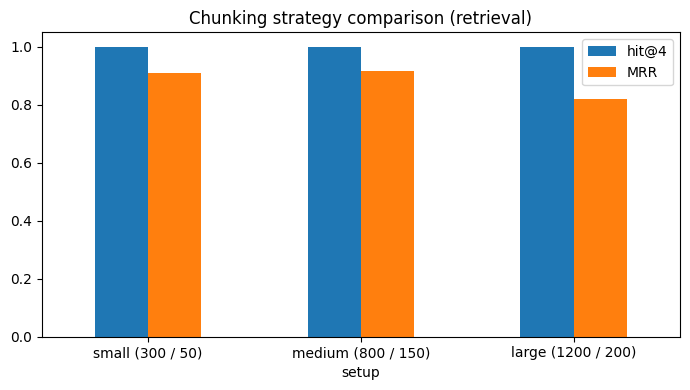

In [ ]:
configs = {
    "small (300 / 50)":   (300, 50),
    "medium (800 / 150)": (800, 150),
    "large (1200 / 200)": (1200, 200),
}

def retrieval_scores(store, k=TOP_K):
    hits, rr = [], []
    for q in IN_DOMAIN:
        got = [d.metadata["page"] for d in store.similarity_search(q["question"], k=k)]
        first = next((i for i, pg in enumerate(got, 1) if pg in q["target_pages"]), None)
        hits.append(first is not None)
        rr.append(1 / first if first else 0.0)
    return float(np.mean(hits)), float(np.mean(rr))

comp_rows = []
for name, (size, overlap) in configs.items():
    sp = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap,
                                        separators=["\n\n", "\n", ". ", " ", ""])
    cfg_chunks = sp.split_documents(pages)
    store = FAISS.from_documents(cfg_chunks, embeddings)
    hit, mrr = retrieval_scores(store)
    comp_rows.append({"setup": name, "chunks": len(cfg_chunks),
                      f"hit@{TOP_K}": round(hit, 3), "MRR": round(mrr, 3)})

comp_df = pd.DataFrame(comp_rows)
comp_df.to_csv("chunk_comparison.csv", index=False)
print(comp_df.to_string(index=False))

ax = comp_df.set_index("setup")[[f"hit@{TOP_K}", "MRR"]].plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Chunking strategy comparison (retrieval)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Step 8 — Chatbot interface
The required interface is a **CLI chat** (the brief accepts CLI). A simple Streamlit app is also written to `app.py` for anyone who wants a web UI; it loads the saved FAISS index, so it needs no re-indexing.

In [ ]:
def chat_cli():
    """Simple terminal-style chatbot. Type 'exit' to stop."""
    print("IIA HR Policy Assistant - ask a question (type 'exit' to quit)\n")
    while True:
        question = input("You: ").strip()
        if question.lower() in {"exit", "quit", "q"}:
            print("Goodbye!")
            break
        if not question:
            continue
        r = rag_answer(question)
        print("\nBot:", r["answer"])
        print("Pages retrieved:", sorted(set(r["pages"])), "\n")

# Uncomment the next line to chat interactively:
# chat_cli()

IIA HR Policy Assistant - ask a question (type 'exit' to quit)

You: what actions can be taken on me if i stop going to company

Bot: Based on the IIA HR Policy document:
- Unauthorized absence or absence without permission from duty for a continuous period for 7 days would make a person to lose his job as a matter of indiscipline (p. 17).
- An employee who is absent for 15 consecutive work days without notice is deemed to have quit, which constitutes a resignation by the employee, and if any dues are to be recovered, action will be taken as per the Law of the Land (p. 18).
Pages retrieved: [17, 18, 21]

## Documentation — architecture diagram, README and requirements

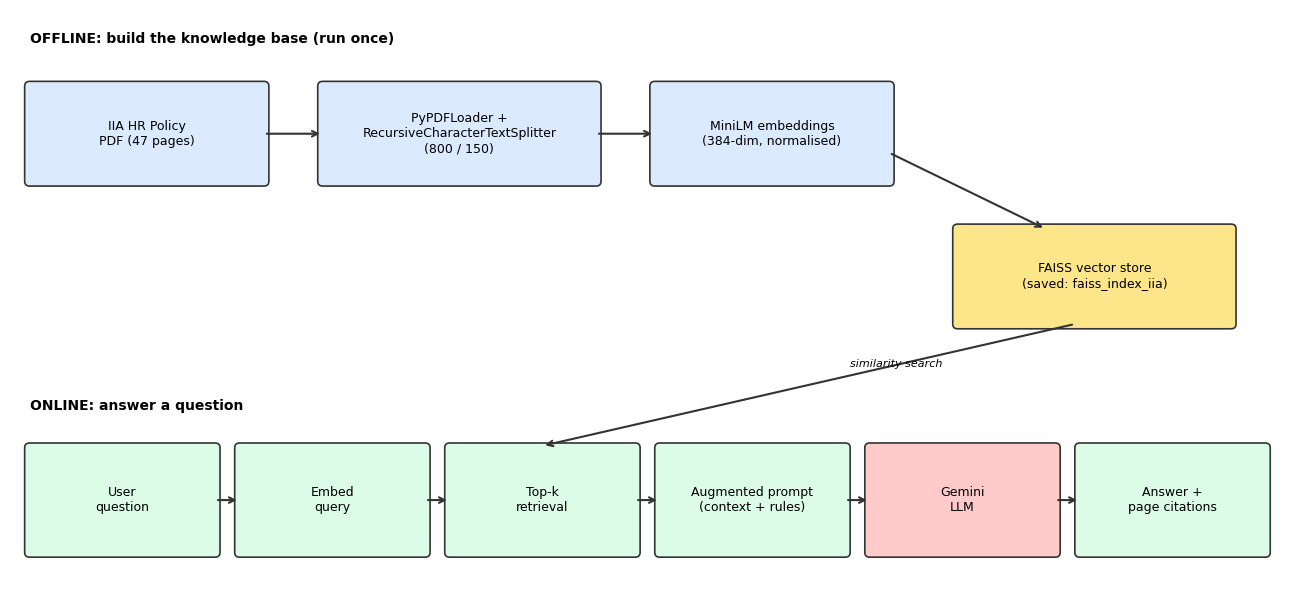

In [ ]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 6.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off")

def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.5, color="#333333"))

ax.text(0.2, 5.85, "OFFLINE: build the knowledge base (run once)", fontsize=10, fontweight="bold")
box(0.2, 4.4, 2.4, 1.0, "IIA HR Policy\nPDF (47 pages)", "#dbeafe")
box(3.2, 4.4, 2.8, 1.0, "PyPDFLoader +\nRecursiveCharacterTextSplitter\n(800 / 150)", "#dbeafe")
box(6.6, 4.4, 2.4, 1.0, "MiniLM embeddings\n(384-dim, normalised)", "#dbeafe")
arrow(2.6, 4.9, 3.2, 4.9); arrow(6.0, 4.9, 6.6, 4.9)
box(9.7, 2.9, 2.8, 1.0, "FAISS vector store\n(saved: faiss_index_iia)", "#fde68a")
arrow(9.0, 4.7, 10.6, 3.9)

ax.text(0.2, 2.0, "ONLINE: answer a question", fontsize=10, fontweight="bold")
names = ["User\nquestion", "Embed\nquery", "Top-k\nretrieval", "Augmented prompt\n(context + rules)", "Gemini\nLLM", "Answer +\npage citations"]
colors = ["#dcfce7", "#dcfce7", "#dcfce7", "#dcfce7", "#fecaca", "#dcfce7"]
xs = [0.2, 2.35, 4.5, 6.65, 8.8, 10.95]
for x, n, c in zip(xs, names, colors):
    box(x, 0.5, 1.9, 1.1, n, c)
for x in xs[:-1]:
    arrow(x + 1.9, 1.05, x + 2.15, 1.05)
arrow(10.9, 2.9, 5.45, 1.62)
ax.text(8.6, 2.45, "similarity search", fontsize=8, style="italic")

plt.tight_layout()
plt.savefig("architecture.png", dpi=150)
plt.show()

In [ ]:
def fmt(key, pct=False, scale5=False):
    v = EVAL_SUMMARY.get(key)
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "not run"
    if pct:
        return f"{v:.0%}"
    if scale5:
        return f"{v:.2f} / 5"
    return f"{v:.3f}"

README_HEAD = """# IIA HR Policy Assistant — RAG Chatbot

A Retrieval-Augmented Generation (RAG) chatbot that answers questions about the **Indian Industries Association (IIA) HR Policy, Revision 1.1** using only the official document, and cites the pages it used. Built for the DataMites AI Engineering Track, AI Client Project 5.

## Problem and knowledge base
Employees need exact answers (leave limits, notice period, loans, transfers, discipline). A plain LLM does not know IIA's policy and hallucinates numbers, so the answers are grounded in the policy PDF (47 pages, 18 sections + 9 annexures). If the document does not contain the answer, the bot says so.

## Architecture
![Architecture](architecture.png)

```
PDF -> PyPDFLoader -> text splitter (800/150) -> MiniLM embeddings -> FAISS index (saved)
question -> embed query -> top-k chunks -> prompt (context + rules) -> Gemini -> answer + pages
```

| Component | Choice |
|---|---|
| Orchestration | LangChain |
| Loader / splitter | PyPDFLoader, RecursiveCharacterTextSplitter (800 chars, 150 overlap) |
| Embeddings | sentence-transformers/all-MiniLM-L6-v2 (local, free) |
| Vector store | FAISS (saved to `faiss_index_iia/`) |
| LLM | Google Gemini via langchain-google-genai |
| Evaluation | RAGAS + retrieval hit-rate/MRR + LLM-as-judge |
| Interface | CLI chat function|

## Files
| File | Purpose |
|---|---|
| `RAG_final.ipynb` | Complete pipeline, evaluation and documentation |
| `faiss_index_iia/` | Saved FAISS index (reproducible vector store) |
| `rag_results.csv`, `ragas_scores.csv`, `chunk_comparison.csv` | Evaluation outputs |
| `architecture.png` | Architecture diagram |
| `requirements.txt` | Python dependencies |

## Setup
1. Python 3.10+ (Google Colab works out of the box).
2. `pip install -r requirements.txt`
3. Get a free Gemini API key from https://aistudio.google.com/apikey

## How to run
**Notebook (Colab):** open `RAG_final.ipynb`, run all cells top to bottom, paste your API key when asked, and upload the IIA HR Policy PDF when asked.

**Chat in the notebook:** uncomment `chat_cli()` in the interface cell.

## Evaluation
17 test questions: 12 single-topic,1 list-type, 1 multi-section, 3 out-of-domain.

"""

README_RESULTS = f"""| Metric | Result |
|---|---|
| Retrieval hit@{TOP_K} (in-domain) | {fmt('hit_at_k', pct=True)} |
| Retrieval MRR | {fmt('mrr')} |
| RAGAS faithfulness | {fmt('faithfulness')} |
| RAGAS answer relevancy | {fmt('answer_relevancy')} |
| RAGAS context precision | {fmt('context_precision')} |
| RAGAS context recall | {fmt('context_recall')} |
| Out-of-domain questions refused | {fmt('ood_refusal_rate', pct=True)} |
| In-domain questions wrongly refused | {fmt('false_refusal_rate', pct=True)} |
| LLM-judge faithfulness (second opinion) | {fmt('judge_faithfulness_5', scale5=True)} |
| LLM-judge relevance (second opinion) | {fmt('judge_relevance_5', scale5=True)} |

"""

README_TAIL = """## Limitations
- Chunking is character-based and the embedding model is small; very long multi-section answers can miss a passage.
- The free Gemini tier is rate limited, so evaluation runs slowly.
- Ground-truth answers were written from the policy text and should be re-checked when the policy is revised.
- Scanned (image-only) PDF pages would need OCR.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(README_HEAD + README_RESULTS + README_TAIL)

REQUIREMENTS = """langchain>=0.3,<0.4
langchain-core>=0.3,<0.4
langchain-community>=0.3,<0.4
langchain-text-splitters>=0.3,<0.4
langchain-huggingface>=0.3,<0.4
langchain-google-genai>=2.1,<3
faiss-cpu
pypdf
sentence-transformers
ragas==0.2.15
datasets
pandas
matplotlib
"""
with open("requirements.txt", "w") as f:
    f.write(REQUIREMENTS)

print("README.md and requirements.txt written.")
print(README_RESULTS)

README.md and requirements.txt written.
| Metric | Result |
|---|---|
| Retrieval hit@4 (in-domain) | 100% |
| Retrieval MRR | 0.917 |
| RAGAS faithfulness | 0.929 |
| RAGAS answer relevancy | 0.719 |
| RAGAS context precision | 0.798 |
| RAGAS context recall | 0.851 |
| Out-of-domain questions refused | 100% |
| In-domain questions wrongly refused | 7% |
| LLM-judge faithfulness (second opinion) | 4.71 / 5 |
| LLM-judge relevance (second opinion) | 4.71 / 5 |




## Summary
The notebook implements the full RAG pipeline from the brief — ingestion, chunking, embeddings, a saved FAISS vector store, retrieval, a grounded Gemini prompt with page citations, a chat interface, and an evaluation on 17 questions with RAGAS (faithfulness, answer relevancy, context precision, context recall), retrieval metrics, an out-of-domain refusal test and a chunk-size comparison. The README, architecture diagram and requirements file are generated by the notebook itself.

## Results, Conclusion and What I Learned

**Results at a glance** (17 questions: 14 in-domain, 3 out-of-domain)

| Metric | Result |
|---|---|
| Retrieval hit@4 / MRR | 100% / 0.917 |
| RAGAS faithfulness | 0.929 |
| RAGAS answer relevancy | 0.719 |
| RAGAS context precision / recall | 0.798 / 0.851 |
| Out-of-domain questions refused | 3 of 3 |
| In-domain questions wrongly refused | 1 of 14 (Q3) |

**Conclusion.** The chatbot retrieves the correct policy page for every in-domain question and answers from it with page citations. Answers were faithful to the retrieved text (0.93), and questions outside the policy were refused instead of guessed. Chunks of 800 characters with 150 overlap gave the best ranking.

**Error analysis.** Q3 (discipline) is the one failure. The correct page was retrieved at rank 1, but the bot replied "I cannot find this" because most likely  the prompt tells it to refuse when unsure. This lowers answer relevancy; without Q3 it would be about 0.77. Weaker precision on Q6, Q7, Q9 and Q12 comes from extra chunks that are not needed for single-fact questions.

**What I learned**
- RAG keeps facts in the document and makes every answer checkable by page number.
- Chunk size matters: very large chunks ranked worse.
- Ground truths must be checked against the source PDF; answers from other AI tools were not safe to use unverified.
- RAGAS needs ground truths for precision and recall, but not for faithfulness and relevancy.
- A strict "answer only from context" prompt reduces hallucination but can cause wrong refusals.
- Judging answers with the same model family gives higher scores than RAGAS.
- Free-tier rate limits need waiting and retry logic.

**Limitations and future work.** One wrong refusal (Q3); blank or image-only pages (43, 47) are not searchable; only 17 test questions. Next steps: soften the refusal rule, use MMR or reranking to avoid noisy chunks, and add a Streamlit interface.